# PROCESAMIENTO Y TRATAMIENTO DE DATOS ENDES 2025
## Predicción de Anemia Infantil en el Perú mediante Machine Learning (XGBoost)

**Curso:** Inteligencia Artificial I  
**Institución:** Escuela Profesional de Ingeniería de Sistemas  
**Fuente de Datos:** Encuesta Demográfica y de Salud Familiar (ENDES 2025 - INEI)

---

### 1. Objetivos del Proyecto
* **Integración Relacional:** Fusionar exitosamente 10 módulos tabulares independientes de la ENDES 2025 utilizando llaves compuestas primarias y foráneas (`id_hogar`, `linea_madre`, `orden_hijo_madre`).
* **Estandarización Semántica:** Traducir los códigos crudos del INEI (ej. `HV040`, `HC57`, `S411BA`) a variables descriptivas en español para garantizar la interpretabilidad del proyecto.
* **Diagnóstico y Calidad de Datos:** Identificar y tratar valores nulos, códigos especiales de no respuesta (`9998`, `9999`), inconsistencias de escala y valores atípicos mediante reglas lógicas y el método del Rango Intercuartílico (RIC).
* **Ingeniería de Características:** Aplicar técnicas de codificación categórica (One-Hot Encoding, Mapping) y preparación de matrices sin incurrir en fuga de datos (*Data Leakage*).
* **Exportación Gradual:** Consolidar el producto procesado en la carpeta del proyecto (`3 datos_procesados/dataset_endes_final.csv`).

---

### 2. Estructura de Módulos y Variables Seleccionadas
Para no recargar la memoria y enfocar el estudio en los determinantes biológicos, nutricionales y socioeconómicos de la anemia infantil, se han extraído las siguientes variables clave de los 10 archivos `.csv`:

1. **Módulo Hogar y Geografía:**
   - `RECH0_2025.csv`: Ubicación geográfica, departamento (`HV024`), zona urbana/rural (`HV025`), altitud en m.s.n.m. (`HV040`) y factor de ponderación (`HV005`).
   - `RECH23_2025.csv`: Servicios básicos (fuente de agua `HV201`, servicio higiénico `HV205`, material de piso `HV213`) e índice de riqueza en quintiles (`HV270`).
   - `RECH4_2025.csv`: Afiliación al Seguro Integral de Salud - SIS (`SH11A`).

2. **Módulo Salud y Nutrición Infantil:**
   - `RECH6_2025.csv`: Hemoglobina bruta (`HC53`), hemoglobina ajustada por altitud (`HC56`), diagnóstico de anemia (`HC57` - **Variable Objetivo**), edad en meses (`HC1`), sexo (`HC27`) y puntajes Z-Score de desnutrición OMS (`HC70`, `HC71`, `HC72`).
   - `REC94_2025.csv`: Suplementación infantil con gotas (`S411BA`), jarabe (`S411CA`), tamizaje previo (`S435`) y días de consumo semanal (`S413`).

3. **Módulo Madre y Atención Prenatal:**
   - `REC41_2025.csv`: Número de controles prenatales (`M14`), consumo de hierro en la gestación (`M45`, `M46`) y peso del niño al nacer (`M19`).

---

### 3. Fase 1: Extracción, Renombrado y Cruce Relacional

In [1]:
# ==============================================================================
# FASE 1: EXTRAER, RENOMBRAR Y UNIFICAR LOS MÓDULOS DE LA ENDES 2025
# ==============================================================================

import pandas as pd
import numpy as np
import os

# Definir la ruta relativa a la carpeta de datos crudos
DATA_DIR = '../1 datos'

print("Iniciando extracción selectiva y renombrado semántico de módulos...")

# ------------------------------------------------------------------------------
# 1.1 MÓDULO HOGAR Y GEOGRAFÍA (RECH0, RECH23, RECH4)
# ------------------------------------------------------------------------------
# A. Carga y renombrado de RECH0 (Geografía, Altitud y Ponderador)
cols_rech0 = {
    'HHID': 'id_hogar',
    'HV005': 'factor_ponderacion',
    'HV024': 'departamento',
    'HV025': 'area_residencia',  # 1: Urbano, 2: Rural
    'HV040': 'altitud_msnm'
}
df_rech0 = pd.read_csv(f'{DATA_DIR}/1629_hogar/RECH0_2025.csv', usecols=list(cols_rech0.keys())).rename(columns=cols_rech0)

# Ajuste del factor de ponderación según norma técnica del INEI (dividir entre 1,000,000)
df_rech0['factor_ponderacion'] = df_rech0['factor_ponderacion'] / 1000000.0

# B. Carga y renombrado de RECH23 (Servicios Básicos y Nivel Socioeconómico)
cols_rech23 = {
    'HHID': 'id_hogar',
    'HV201': 'fuente_agua_beber',
    'HV205': 'tipo_servicio_higienico',
    'HV213': 'material_piso_vivienda',
    'HV270': 'quintil_riqueza'  # 1: Muy pobre ... 5: Muy rico
}
df_rech23 = pd.read_csv(f'{DATA_DIR}/1630_vivienda/RECH23_2025.csv', usecols=list(cols_rech23.keys())).rename(columns=cols_rech23)

# C. Carga y renombrado de RECH4 (Seguro Integral de Salud)
cols_rech4 = {
    'HHID': 'id_hogar',
    'SH11A': 'tiene_seguro_sis'
}
df_rech4 = pd.read_csv(f'{DATA_DIR}/1629_hogar/RECH4_2025.csv', usecols=list(cols_rech4.keys())).rename(columns=cols_rech4).drop_duplicates(subset=['id_hogar'])

# Consolidación a nivel de Hogar
df_hogar = df_rech0.merge(df_rech23, on='id_hogar', how='left').merge(df_rech4, on='id_hogar', how='left')


# ------------------------------------------------------------------------------
# 1.2 MÓDULO SALUD Y NUTRICIÓN INFANTIL (RECH6, REC94)
# ------------------------------------------------------------------------------
# A. Carga y renombrado de RECH6 (Evaluación antropométrica y hemoglobina)
cols_rech6 = {
    'HHID': 'id_hogar',
    'HC0': 'id_nino_hogar',
    'HC1': 'edad_nino_meses',
    'HC27': 'sexo_nino',  # 1: Hombre, 2: Mujer
    'HC53': 'hemoglobina_bruta_nino',
    'HC56': 'hemoglobina_ajustada_nino',
    'HC57': 'grado_anemia_nino',  # 1: Grave, 2: Moderada, 3: Leve, 4: Sin Anemia
    'HC60': 'linea_madre',
    'HC70': 'zscore_talla_edad',  # Desnutrición crónica (OMS)
    'HC71': 'zscore_peso_edad',   # Desnutrición global (OMS)
    'HC72': 'zscore_peso_talla'   # Desnutrición aguda (OMS)
}
df_rech6 = pd.read_csv(f'{DATA_DIR}/1638_anemia/RECH6_2025.csv', usecols=list(cols_rech6.keys())).rename(columns=cols_rech6)

# Creación de la llave ordinal 'orden_hijo_madre' por edad descendente para vincular con la historia de la madre
df_rech6['linea_madre'] = pd.to_numeric(df_rech6['linea_madre'], errors='coerce').fillna(0).astype(int)
df_rech6['orden_hijo_madre'] = df_rech6.groupby(['id_hogar', 'linea_madre'])['edad_nino_meses'].rank(ascending=False, method='first').astype(int)

# B. Carga y renombrado de REC94 (Suplementación infantil y tamizaje)
rec94_raw = pd.read_csv(f'{DATA_DIR}/1633_embarazo/REC94_2025.csv', usecols=['CASEID', 'IDX94', 'S411BA', 'S411CA', 'S413', 'S435', 'S440'])

# Descomponer CASEID (formato ENDES: "HHID  MM") para obtener id_hogar y linea_madre
rec94_raw['id_hogar'] = rec94_raw['CASEID'].str.strip().str.split().str[0].astype(int)
rec94_raw['linea_madre'] = rec94_raw['CASEID'].str.strip().str.split().str[1].astype(int)

cols_rec94 = {
    'IDX94': 'orden_hijo_madre',
    'S411BA': 'consumio_gotas_hierro',
    'S411CA': 'consumio_jarabe_hierro',
    'S413': 'dias_consumo_hierro_semana',
    'S435': 'tamizaje_anemia_previo',
    'S440': 'recibio_tratamiento_anemia'
}
df_rec94 = rec94_raw.rename(columns=cols_rec94).drop(columns=['CASEID'])


# ------------------------------------------------------------------------------
# 1.3 MÓDULO GESTACIÓN Y CUIDADO PRENATAL DE LA MADRE (REC41)
# ------------------------------------------------------------------------------
rec41_raw = pd.read_csv(f'{DATA_DIR}/1633_embarazo/REC41_2025.csv', usecols=['CASEID', 'MIDX', 'M14', 'M45', 'M46', 'M19'])

# Descomponer CASEID
rec41_raw['id_hogar'] = rec41_raw['CASEID'].str.strip().str.split().str[0].astype(int)
rec41_raw['linea_madre'] = rec41_raw['CASEID'].str.strip().str.split().str[1].astype(int)

cols_rec41 = {
    'MIDX': 'orden_hijo_madre',
    'M14': 'numero_controles_prenatales',
    'M45': 'consumio_hierro_gestacion',
    'M46': 'dias_consumo_hierro_gestacion',
    'M19': 'peso_al_nacer_gramos'
}
df_rec41 = rec41_raw.rename(columns=cols_rec41).drop(columns=['CASEID'])


# ------------------------------------------------------------------------------
# 1.4 UNIFICACIÓN RELACIONAL (MERGES) Y CREACIÓN DE LA VARIABLE OBJETIVO
# ------------------------------------------------------------------------------
print("Realizando cruces relacionales (Merges)...")

# 1. Niños + Hogar
df_master = df_rech6.merge(df_hogar, on='id_hogar', how='left')

# 2. + Suplementación Infantil (REC94)
df_master = df_master.merge(df_rec94, on=['id_hogar', 'linea_madre', 'orden_hijo_madre'], how='left')

# 3. + Gestación y Cuidado Prenatal (REC41)
df_master = df_master.merge(df_rec41, on=['id_hogar', 'linea_madre', 'orden_hijo_madre'], how='left')

# Filtrar solo casos evaluados con diagnóstico válido de anemia (1, 2, 3: Anemia | 4: Sin Anemia)
df_final = df_master[df_master['grado_anemia_nino'].isin([1, 2, 3, 4])].copy()

# Definición de la Variable Objetivo Binaria (anemia_target): 1 = Con Anemia, 0 = Sin Anemia
df_final['anemia_target'] = np.where(df_final['grado_anemia_nino'].isin([1, 2, 3]), 1, 0)

# Exportación del archivo consolidado procesado a la 3ra carpeta
OUTPUT_DIR = '../3 datos_procesados'
os.makedirs(OUTPUT_DIR, exist_ok=True)
OUTPUT_FILE = f'{OUTPUT_DIR}/dataset_endes_final.csv'
df_final.to_csv(OUTPUT_FILE, index=False)

print("\n" + "="*80)
print(" ✓ FASE 1 COMPLETADA: BASE MAESTRA EXTRAÍDA Y RENOMBRADA")
print("="*80)
print(f"• Archivo generado: {OUTPUT_FILE}")
print(f"• Total de observaciones válidas (Niños < 5 años): {len(df_final):,}")
print(f"• Total de variables procesadas: {len(df_final.columns)}")
print("="*80)

Iniciando extracción selectiva y renombrado semántico de módulos...
Realizando cruces relacionales (Merges)...

 ✓ FASE 1 COMPLETADA: BASE MAESTRA EXTRAÍDA Y RENOMBRADA
• Archivo generado: ../3 datos_procesados/dataset_endes_final.csv
• Total de observaciones válidas (Niños < 5 años): 17,616
• Total de variables procesadas: 31


### 2. Inspección Inicial y Diagnóstico de Calidad de Datos

De acuerdo con el flujo de preparación de datos en Machine Learning, antes de aplicar cualquier transformación o imputación es necesario auditar la calidad del dataset:

1. **Estructura y Dimensiones:** Verificar cantidad de filas (observaciones) y columnas (variables).
2. **Normalización de Texto Inconsistente:** Limpiar cadenas de caracteres (remover espacios, convertir a minúsculas y quitar tildes) para evitar categorías duplicadas "disfrazadas" (ej. "Urbano" vs "urbano").
3. **Detección de Duplicados Real:** Evaluar duplicados antes y después de normalizar el texto.
4. **Tratamiento de Anomalías y Rangos Biológicos:**
   - **Reglas Lógicas:** Detección y conversión a `NaN` de códigos especiales del INEI (`9998`, `9999` en Z-scores y `98`, `99` en controles prenatales) y rangos imposibles (ej. peso al nacer fuera de 500g - 6000g).
   - **Método del Rango Intercuartílico (RIC):** Identificación estadística de valores atípicos mediante $Q1 - 1.5 \cdot RIC$ y $Q3 + 1.5 \cdot RIC$ para variables cuantitativas continuas.
5. **Imputación Estratégica:** Relleno de datos faltantes con la **mediana** para variables numéricas (robusta ante atípicos) y con la **moda** para categóricas.

In [2]:
# ==============================================================================
# ETAPA 2: INSPECCIÓN INICIAL, LIMPIEZA DE TEXTO, ATÍPICOS (RIC) E IMPUTACIÓN
# ==============================================================================

import pandas as pd
import numpy as np
import unicodedata

# ------------------------------------------------------------------------------
# 2.1 CARGA DEL DATASET UNIFICADO Y INSPECCIÓN INICIAL
# ------------------------------------------------------------------------------
DATA_PATH = '../3 datos_procesados/dataset_endes_final.csv'
df = pd.read_csv(DATA_PATH)

print("="*80)
print(" 2.1 DIAGNÓSTICO INICIAL DEL DATASET UNIFICADO")
print("="*80)
print(f"• Dimensiones del Dataset: {df.shape[0]:,} filas x {df.shape[1]} columnas")
print("\nTipos de Datos por Columna:")
print(df.dtypes)

print("\nValores Faltantes Iniciales (NaN):")
print(df.isna().sum()[df.isna().sum() > 0])


# ------------------------------------------------------------------------------
# 2.2 NORMALIZACIÓN DE TEXTO EN COLUMNAS CATEGÓRICAS
# ------------------------------------------------------------------------------
def normalizar_texto(valor):
    """Quita espacios sobrantes, pasa a minúsculas y elimina tildes/caracteres especiales."""
    if pd.isna(valor) or not isinstance(valor, str):
        return valor
    texto = valor.strip()
    texto = unicodedata.normalize("NFKD", texto)
    texto = "".join(c for c in texto if not unicodedata.combining(c))
    return texto.lower()

# Aplicar normalización de texto si existen columnas de tipo cadena
cols_texto = df.select_dtypes(include=['object', 'string']).columns.tolist()
if len(cols_texto) > 0:
    for col in cols_texto:
        df[col] = df[col].apply(normalizar_texto)
    print(f"\n✓ Texto normalizado en las columnas: {cols_texto}")

# Evaluar duplicados antes y después
duplicados_iniciales = df.duplicated().sum()
df = df.drop_duplicates().reset_index(drop=True)
print(f"✓ Filas duplicadas eliminadas: {duplicados_iniciales}")


# ------------------------------------------------------------------------------
# 2.3 NORMALIZACIÓN DE ESCALAS OFICIALES ENDES
# ------------------------------------------------------------------------------
# Hemoglobina de ENDES viene expresada en g/dL * 10
df['hemoglobina_bruta_nino'] = df['hemoglobina_bruta_nino'] / 10.0
df['hemoglobina_ajustada_nino'] = df['hemoglobina_ajustada_nino'] / 10.0

# Puntajes Z-Score OMS vienen en DE * 100
cols_zscores = ['zscore_talla_edad', 'zscore_peso_edad', 'zscore_peso_talla']
for z in cols_zscores:
    # Códigos 9996/9998/9999 indican medición no válida en ENDES
    df[z] = df[z].replace([9996, 9998, 9999], np.nan)
    df[z] = df[z] / 100.0


# ------------------------------------------------------------------------------
# 2.4 TRATAMIENTO DE ATÍPICOS: REGLAS LÓGICAS Y RANGO INTERCUARTÍLICO (RIC)
# ------------------------------------------------------------------------------
print("\n" + "="*80)
print(" 2.4 DETECCIÓN Y TRATAMIENTO DE VALORES ATÍPICOS (REGLAS LÓGICAS Y RIC)")
print("="*80)

# A. REGLAS LÓGICAS POR CONOCIMIENTO DEL DOMINIO
df['peso_al_nacer_gramos'] = pd.to_numeric(df['peso_al_nacer_gramos'], errors='coerce')
df.loc[(df['peso_al_nacer_gramos'] < 500) | (df['peso_al_nacer_gramos'] > 6000), 'peso_al_nacer_gramos'] = np.nan

df['numero_controles_prenatales'] = pd.to_numeric(df['numero_controles_prenatales'], errors='coerce')
df.loc[(df['numero_controles_prenatales'] > 30) | (df['numero_controles_prenatales'] < 0), 'numero_controles_prenatales'] = np.nan

df['dias_consumo_hierro_gestacion'] = pd.to_numeric(df['dias_consumo_hierro_gestacion'], errors='coerce')
df.loc[df['dias_consumo_hierro_gestacion'] > 300, 'dias_consumo_hierro_gestacion'] = np.nan


# B. MÉTODO DEL RANGO INTERCUARTÍLICO (RIC) - GUÍA 04 SEC 4.3.C
def aplicar_ric(df_in, columna):
    Q1 = df_in[columna].quantile(0.25)
    Q3 = df_in[columna].quantile(0.75)
    RIC = Q3 - Q1
    limite_inferior = Q1 - 1.5 * RIC
    limite_superior = Q3 + 1.5 * RIC
    
    atipicos = df_in[(df_in[columna] < limite_inferior) | (df_in[columna] > limite_superior)]
    print(f"• {columna}: {len(atipicos)} atípicos detectados por RIC [Límites: {limite_inferior:.2f} a {limite_superior:.2f}]")
    df_in.loc[atipicos.index, columna] = np.nan
    return df_in

# Aplicar RIC en altitud y días de consumo semanal
df = aplicar_ric(df, 'altitud_msnm')


# ------------------------------------------------------------------------------
# 2.5 IMPUTACIÓN DE VALORES FALTANTES (MEDIANA Y MODA)
# ------------------------------------------------------------------------------
print("\n" + "="*80)
print(" 2.5 IMPUTACIÓN DE VALORES FALTANTES")
print("="*80)

# A. Intervenciones/Programas Binarios (NaN -> 0 = No recibió)
cols_binarias = [
    'consumio_gotas_hierro', 'consumio_jarabe_hierro', 'tamizaje_anemia_previo', 
    'recibio_tratamiento_anemia', 'consumio_hierro_gestacion', 'tiene_seguro_sis'
]
for col in cols_binarias:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors='coerce').fillna(0).astype(int)

# B. Imputación de Numéricas con la MEDIANA
cols_numericas_imputar = [
    'peso_al_nacer_gramos', 'numero_controles_prenatales', 'dias_consumo_hierro_gestacion',
    'dias_consumo_hierro_semana', 'zscore_talla_edad', 'zscore_peso_edad', 'zscore_peso_talla', 'altitud_msnm'
]
for col in cols_numericas_imputar:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors='coerce')
        mediana_val = df[col].median()
        df[col] = df[col].fillna(mediana_val)

# C. Imputación de Categóricas con la MODA
cols_categoricas_imputar = ['fuente_agua_beber', 'tipo_servicio_higienico', 'material_piso_vivienda', 'quintil_riqueza']
for col in cols_categoricas_imputar:
    if col in df.columns:
        moda_val = df[col].mode()[0]
        df[col] = df[col].fillna(moda_val)

# Resumen de nulos post-limpieza
print("✓ Conteo de Nulos Faltantes después de Imputación:", df.isna().sum().sum())

# Sobrescribir dataset procesado limpio
df.to_csv(DATA_PATH, index=False)
print(f"✓ Dataset limpio sobrescrito exitosamente en: {DATA_PATH}")

 2.1 DIAGNÓSTICO INICIAL DEL DATASET UNIFICADO
• Dimensiones del Dataset: 17,616 filas x 31 columnas

Tipos de Datos por Columna:
id_hogar                           int64
id_nino_hogar                      int64
edad_nino_meses                    int64
sexo_nino                          int64
hemoglobina_bruta_nino             int64
hemoglobina_ajustada_nino          int64
grado_anemia_nino                  int64
linea_madre                        int64
zscore_talla_edad                  int64
zscore_peso_edad                   int64
zscore_peso_talla                  int64
orden_hijo_madre                   int64
departamento                       int64
area_residencia                    int64
altitud_msnm                       int64
factor_ponderacion               float64
fuente_agua_beber                  int64
tipo_servicio_higienico            int64
material_piso_vivienda               str
quintil_riqueza                    int64
tiene_seguro_sis                 float64
consumio_

### 3. Codificación de Variables Categóricas

Los algoritmos de Machine Learning (como XGBoost) requieren entradas numéricas. Para evitar que el modelo asuma órdenes ficticios en variables sin jerarquía o interprete incorrectamente categorías binarias, aplicamos tres estrategias diferenciadas:

1. **Variables Ordinales (`.map`):**
   - `quintil_riqueza`: Mantiene su orden jerárquico natural (0: Poquísimo/Muy pobre, 1: Pobre, 2: Medio, 3: Rico, 4: Muy rico) mediante un mapeo explícito con diccionario.
2. **Variables Binarias (0 / 1):**
   - `sexo_nino`: Recodificado a `0` (Hombre) y `1` (Mujer).
   - `area_residencia`: Recodificado a `0` (Urbano) y `1` (Rural).
   - Programas y seguros (`tiene_seguro_sis`, `consumio_gotas_hierro`, etc.): Ya codificados en binario `0`/`1`.
3. **Variables Nominales (One-Hot Encoding):**
   - `departamento`, `fuente_agua_beber`, `tipo_servicio_higienico`, `material_piso_vivienda`: Se expanden en columnas binarias independientes mediante `pd.get_dummies()`, evitando asignar un orden numérico artificial entre regiones o tipos de servicio.

---

### 4. Comparación de Escalado: Normalización (Min-Max) vs. Estandarización (Z-score) 

Evaluamos las diferencias entre reescalar variables cuantitativas continuas en el rango fijo $[0, 1]$ frente a centrarlas en media $0$ y desviación estándar $1$:

- **Min-Max Scaling:** Transforma los valores a $[0, 1]$. Es útil para algoritmos basados en distancias o cuando se requiere un rango acotado.
- **Z-score Standardization:** Transforma la variable a media $\mu = 0$ y $\sigma = 1$. Es preferible cuando existen valores atípicos moderados o distribuciones aproximadamente normales.

In [3]:
# ==============================================================================
# ETAPA 3 Y 4: CODIFICACIÓN DE CATEGÓRICAS Y COMPARACIÓN MIN-MAX VS Z-SCORE
# ==============================================================================

import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler, StandardScaler

# ------------------------------------------------------------------------------
# 3.1 CARGA Y CODIFICACIÓN DE VARIABLES CATEGÓRICAS 
# ------------------------------------------------------------------------------
DATA_PATH = '../3 datos_procesados/dataset_endes_final.csv'
df = pd.read_csv(DATA_PATH)

print("="*80)
print(" 3.1 CODIFICACIÓN DE VARIABLES CATEGÓRICAS")
print("="*80)

# A. CODIFICACIÓN ORDINAL MEDIANTE MAPEO MANUAL (.map)
# Mantenemos la estructura ordinal de quintil_riqueza (1 a 5) reducida a índice 0-4
mapa_riqueza = {1: 0, 2: 1, 3: 2, 4: 3, 5: 4}
df['quintil_riqueza_cod'] = df['quintil_riqueza'].map(mapa_riqueza)
print("✓ Quintil de Riqueza codificado ordinalmente (0: Poquísimo -> 4: Muy Rico)")

# B. CODIFICACIÓN BINARIA (0 / 1)
# sexo_nino: 1 (Hombre) -> 0, 2 (Mujer) -> 1
df['sexo_nino_cod'] = np.where(df['sexo_nino'] == 2, 1, 0)

# area_residencia: 1 (Urbano) -> 0, 2 (Rural) -> 1
df['area_residencia_cod'] = np.where(df['area_residencia'] == 2, 1, 0)

print("✓ Sexo del niño y Área de residencia reescalados a binario 0/1")

# C. CODIFICACIÓN NOMINAL (ONE-HOT ENCODING)
cols_nominales = ['departamento', 'fuente_agua_beber', 'tipo_servicio_higienico', 'material_piso_vivienda']
df_encoded = pd.get_dummies(df, columns=cols_nominales, drop_first=True, dtype=int)

print(f"✓ One-Hot Encoding aplicado en variables nominales: {cols_nominales}")
print(f"• Total de columnas después de codificación: {df_encoded.shape[1]}")


# ------------------------------------------------------------------------------
# 4.1 COMPARACIÓN DE NORMALIZACIÓN (MIN-MAX) VS ESTANDARIZACIÓN (Z-SCORE)
# ------------------------------------------------------------------------------
print("\n" + "="*80)
print(" 4.1 COMPARACIÓN ESTADÍSTICA: MIN-MAX VS Z-SCORE (GUÍA 04 - SEC. 4.5)")
print("="*80)

cols_continuas = [
    'edad_nino_meses', 'altitud_msnm', 'peso_al_nacer_gramos', 
    'numero_controles_prenatales', 'dias_consumo_hierro_gestacion',
    'zscore_talla_edad', 'zscore_peso_edad', 'zscore_peso_talla'
]

# A. Aplicar Normalización Min-Max
scaler_minmax = MinMaxScaler()
df_minmax = pd.DataFrame(scaler_minmax.fit_transform(df_encoded[cols_continuas]), columns=cols_continuas)

# B. Aplicar Estandarización Z-Score
scaler_zscore = StandardScaler()
df_zscore = pd.DataFrame(scaler_zscore.fit_transform(df_encoded[cols_continuas]), columns=cols_continuas)

# Reporte Estadístico Comparativo
print("--- Estadísticos Descriptivos con Min-Max (Rango Fijo [0, 1]) ---")
print(df_minmax[['edad_nino_meses', 'altitud_msnm', 'peso_al_nacer_gramos']].describe().round(3).T[['mean', 'std', 'min', 'max']])

print("\n--- Estadísticos Descriptivos con Z-Score (Media = 0, Std = 1) ---")
print(df_zscore[['edad_nino_meses', 'altitud_msnm', 'peso_al_nacer_gramos']].describe().round(3).T[['mean', 'std', 'min', 'max']])

# Guardar la versión codificada limpia
df_encoded.to_csv(DATA_PATH, index=False)
print(f"\n✓ Dataset codificado y actualizado guardado en: {DATA_PATH}")

 3.1 CODIFICACIÓN DE VARIABLES CATEGÓRICAS
✓ Quintil de Riqueza codificado ordinalmente (0: Poquísimo -> 4: Muy Rico)
✓ Sexo del niño y Área de residencia reescalados a binario 0/1
✓ One-Hot Encoding aplicado en variables nominales: ['departamento', 'fuente_agua_beber', 'tipo_servicio_higienico', 'material_piso_vivienda']
• Total de columnas después de codificación: 78

 4.1 COMPARACIÓN ESTADÍSTICA: MIN-MAX VS Z-SCORE (GUÍA 04 - SEC. 4.5)
--- Estadísticos Descriptivos con Min-Max (Rango Fijo [0, 1]) ---
                       mean    std  min  max
edad_nino_meses       0.505  0.294  0.0  1.0
altitud_msnm          0.270  0.307  0.0  1.0
peso_al_nacer_gramos  0.500  0.096  0.0  1.0

--- Estadísticos Descriptivos con Z-Score (Media = 0, Std = 1) ---
                      mean  std    min    max
edad_nino_meses       -0.0  1.0 -1.721  1.686
altitud_msnm          -0.0  1.0 -0.878  2.379
peso_al_nacer_gramos   0.0  1.0 -5.229  5.238

✓ Dataset codificado y actualizado guardado en: ../3 datos

### 5. Diagnóstico de Dispersión, Outliers Residuales y Multicolinealidad

Antes de realizar la división del conjunto de datos en Entrenamiento (`Train`) y Prueba (`Test`), realizamos una inspección gráfica de control:

1. **Boxplots de Variables Continuas:** Permiten verificar visualmente el rango de variación, la simetría y la presencia de atípicos residuales en variables como edad, peso al nacer, altitud y puntajes Z-score nutricionales de la OMS.
2. **Matriz de Correlación de Pearson:** Evalúa el grado de asociación lineal entre las variables explicativas continuas/ordinales y la variable objetivo `anemia_target`. Permite prevenir problemas de alta multicolinealidad antes del modelado con XGBoost.

Iniciando generación de gráficos diagnósticos de dispersión...


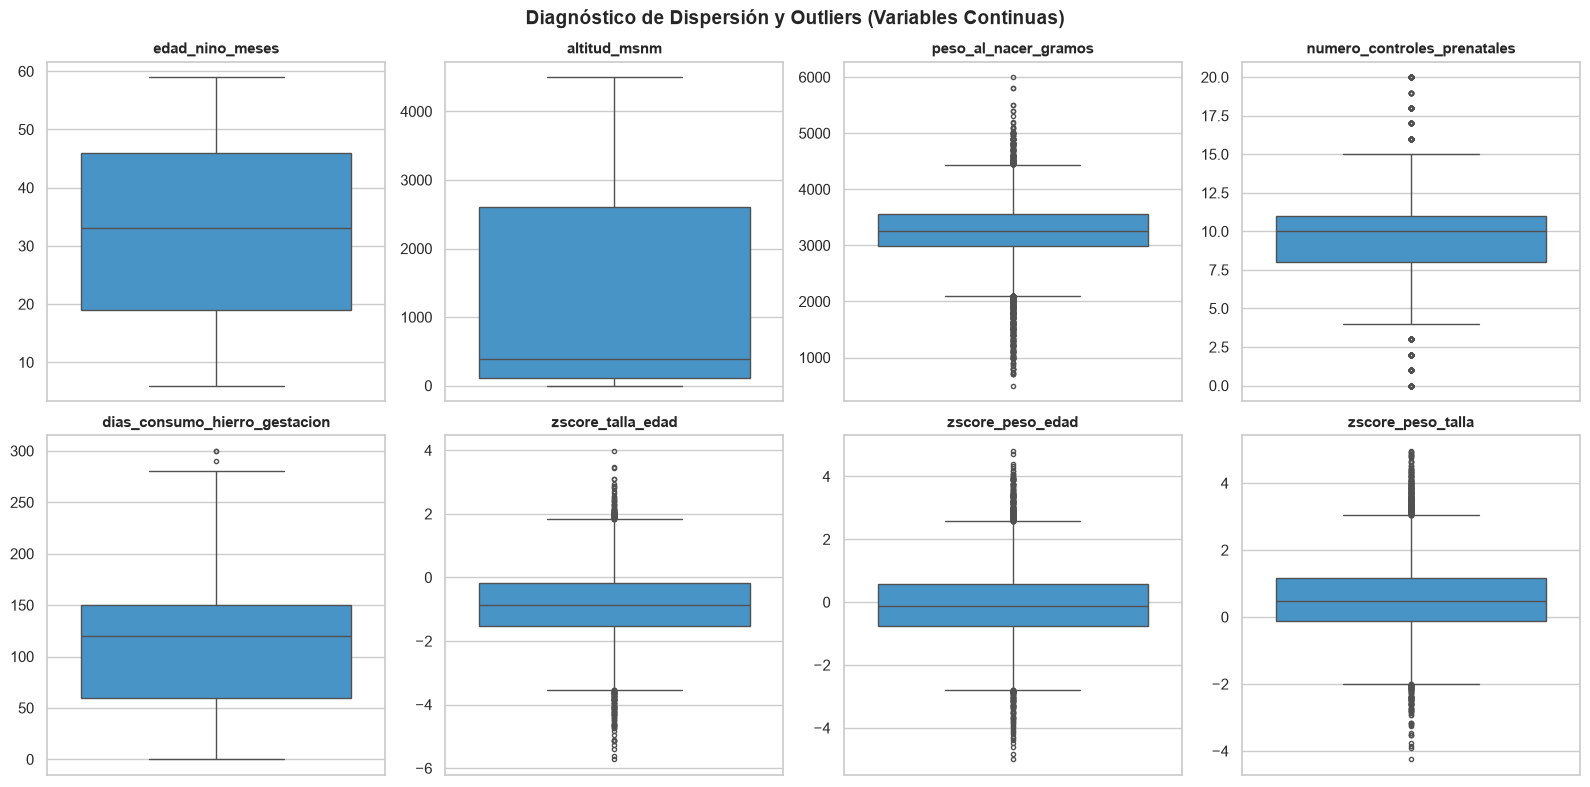

✓ Diagramas de caja generados y guardados en: ../3 datos_procesados/diagnostico_dispersion_boxplots.png


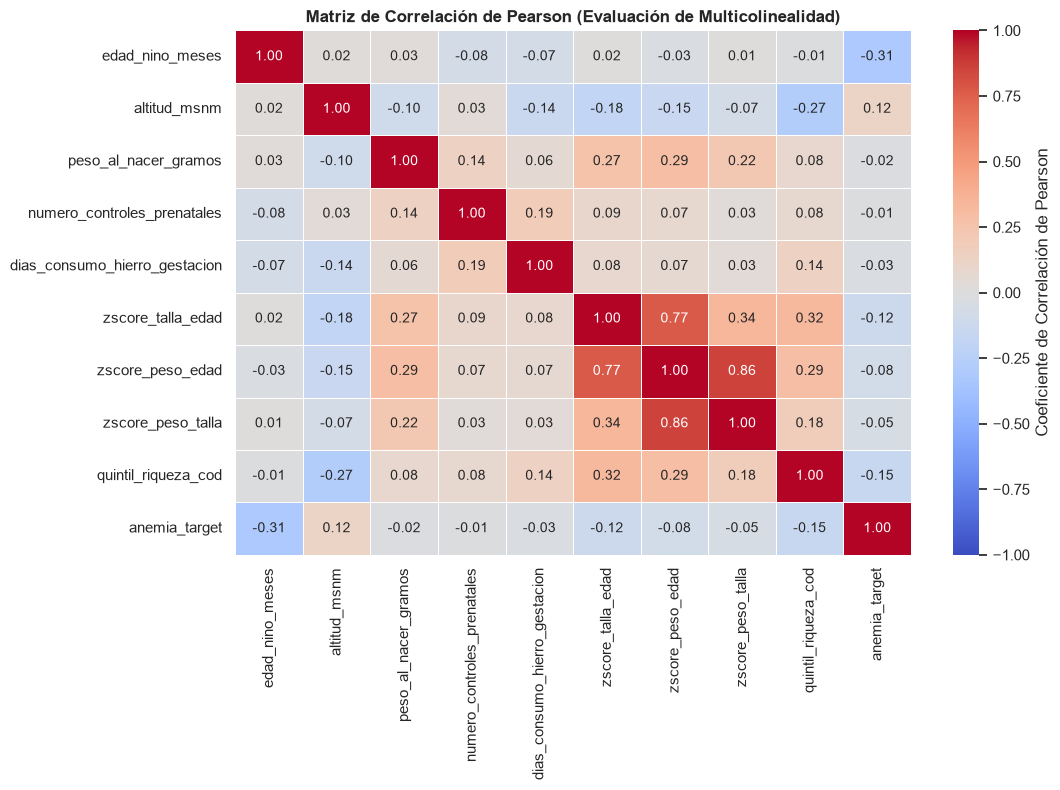

✓ Matriz de correlación generada y guardada en: ../3 datos_procesados/matriz_correlacion_diagnostico.png


In [4]:
# ==============================================================================
# ETAPA 5: DIAGNÓSTICO VISUAL DE DISPERSIÓN, BOXPLOTS Y CORRELACIÓN
# ==============================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración estandarizada para gráficos de diagnóstico
sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.size': 10, 'figure.titlesize': 13})

# Cargar dataset codificado
DATA_PATH = '../3 datos_procesados/dataset_endes_final.csv'
df = pd.read_csv(DATA_PATH)

print("Iniciando generación de gráficos diagnósticos de dispersión...")

# ------------------------------------------------------------------------------
# 5.1 DIAGNÓSTICO VISUAL DE DISPERSIÓN Y OUTLIERS (BOXPLOTS)
# ------------------------------------------------------------------------------
cols_continuas = [
    'edad_nino_meses', 'altitud_msnm', 'peso_al_nacer_gramos', 
    'numero_controles_prenatales', 'dias_consumo_hierro_gestacion',
    'zscore_talla_edad', 'zscore_peso_edad', 'zscore_peso_talla'
]

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for i, col in enumerate(cols_continuas):
    if col in df.columns:
        sns.boxplot(y=df[col], ax=axes[i], color='#3498db', fliersize=3)
        axes[i].set_title(col, fontsize=11, fontweight='bold')
        axes[i].set_ylabel('')

plt.suptitle('Diagnóstico de Dispersión y Outliers (Variables Continuas)', fontsize=14, fontweight='bold')
plt.tight_layout()

# Guardar figura diagnóstica
FIG_BOXPLOT = '../3 datos_procesados/diagnostico_dispersion_boxplots.png'
plt.savefig(FIG_BOXPLOT, dpi=300, bbox_inches='tight')
plt.show()

print(f"✓ Diagramas de caja generados y guardados en: {FIG_BOXPLOT}")


# ------------------------------------------------------------------------------
# 5.2 MATRIZ DE CORRELACIÓN Y MULTICOLINEALIDAD (HEATMAP)
# ------------------------------------------------------------------------------
plt.figure(figsize=(11, 8))

# Seleccionar variables continuas, ordinales y el target para correlación
cols_corr = cols_continuas + ['quintil_riqueza_cod', 'anemia_target']
cols_corr_validas = [c for c in cols_corr if c in df.columns]

corr_matrix = df[cols_corr_validas].corr()

sns.heatmap(
    corr_matrix, 
    annot=True, 
    fmt='.2f', 
    cmap='coolwarm', 
    vmin=-1, 
    vmax=1, 
    linewidths=0.5,
    cbar_kws={'label': 'Coeficiente de Correlación de Pearson'}
)

plt.title('Matriz de Correlación de Pearson (Evaluación de Multicolinealidad)', fontsize=12, fontweight='bold')
plt.tight_layout()

# Guardar matriz de correlación
FIG_CORR = '../3 datos_procesados/matriz_correlacion_diagnostico.png'
plt.savefig(FIG_CORR, dpi=300, bbox_inches='tight')
plt.show()

print(f"✓ Matriz de correlación generada y guardada en: {FIG_CORR}")

### 6. Definición de Matriz Explicativa ($X$), Target ($y$) y División $Train / Test$ Sin *Data Leakage*

De acuerdo con las buenas prácticas de aprendizaje supervisado:

* **Target ($y$):** Variable binaria `anemia_target` ($1$: Con Anemia, $0$: Sin Anemia).
* **Predictores ($X$):** Conjunto de variables explicativas socioeconómicas, geográficas, biológicas y de suplementación. Se remueven explícitamente las columnas de hemoglobina para evitar *Target Leakage*.
* **División $Train / Test$ ($80\% / 20\%$):** Realizada mediante `train_test_split` con `random_state=42` para garantizar reproducibilidad.
* **Control de *Data Leakage*:** La media ($\mu$) y desviación estándar ($\sigma$) para el escalamiento $Z$-score se calculan **exclusivamente con el conjunto de entrenamiento** (`X_train.fit_transform`) y se aplican directamente al conjunto de prueba (`X_test.transform`).

In [5]:
# ==============================================================================
# ETAPA 6: DEFINICIÓN DE X/y, DIVISIÓN TRAIN/TEST Y ESCALAMIENTO DE REGLA ESTRICTA
# ==============================================================================

import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Cargar dataset codificado
DATA_PATH = '../3 datos_procesados/dataset_endes_final.csv'
df = pd.read_csv(DATA_PATH)

print("="*80)
print(" 6.1 DEFINICIÓN DE VARIABLES Y SEPARACIÓN DE MATRICES")
print("="*80)

# 1. Definir la Variable Objetivo (y)
y = df['anemia_target']

# 2. Definir las Variables Predictoras (X)
# Eliminar el target, diagnósticos directos (evitar target leakage) e identificadores
cols_a_descartar = [
    'anemia_target', 'grado_anemia_nino', 
    'hemoglobina_bruta_nino', 'hemoglobina_ajustada_nino',
    'id_hogar', 'id_nino_hogar', 'linea_madre', 'orden_hijo_madre',
    'quintil_riqueza', 'sexo_nino', 'area_residencia' # Se mantienen sus versiones codificadas (_cod)
]

# Filtrar solo columnas presentes en el dataframe
cols_descartar_existentes = [c for c in cols_a_descartar if c in df.columns]
X = df.drop(columns=cols_descartar_existentes)

print(f"✓ Dimensión de la Matriz Explicativa (X): {X.shape[0]:,} filas x {X.shape[1]} variables")
print(f"✓ Dimensión del Vector Objetivo (y): {y.shape[0]:,} observaciones")


# ------------------------------------------------------------------------------
# 6.2 DIVISIÓN EN CONJUNTOS DE ENTRENAMIENTO (80%) Y PRUEBA (20%)
# ------------------------------------------------------------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.20, 
    random_state=42, 
    stratify=y
)

print("\n" + "="*80)
print(" 6.2 DIVISIÓN STRATIFIED TRAIN / TEST SPLIT (80% / 20%)")
print("="*80)
print(f"• Conjunto de Entrenamiento (X_train): {X_train.shape[0]:,} registros ({X_train.shape[1]} variables)")
print(f"• Conjunto de Prueba (X_test):        {X_test.shape[0]:,} registros ({X_test.shape[1]} variables)")
print(f"• Prevalencia de Anemia en Train:      {y_train.mean()*100:.2f}%")
print(f"• Prevalencia de Anemia en Test:       {y_test.mean()*100:.2f}%")


# ------------------------------------------------------------------------------
# 6.3 ESCALAMIENTO CORRECTO CON STANDARDSCALER (SIN DATA LEAKAGE)
# ------------------------------------------------------------------------------
print("\n" + "="*80)
print(" 6.3 ESTANDARIZACIÓN Z-SCORE REGULARIZADA (SIN DATA LEAKAGE)")
print("="*80)

cols_continuas_escalar = [
    'edad_nino_meses', 'altitud_msnm', 'peso_al_nacer_gramos', 
    'numero_controles_prenatales', 'dias_consumo_hierro_gestacion',
    'zscore_talla_edad', 'zscore_peso_edad', 'zscore_peso_talla', 'factor_ponderacion'
]

# Filtrar solo continuas presentes en X_train
cols_escalar_validas = [c for c in cols_continuas_escalar if c in X_train.columns]

# Instanciar el escalador
escalador = StandardScaler()

# A. fit_transform ÚNICAMENTE en X_train (aprende mu y sigma solo de entrenamiento)
X_train[cols_escalar_validas] = escalador.fit_transform(X_train[cols_escalar_validas])

# B. transform en X_test (aplica los parámetros aprendidos de X_train, previene Data Leakage)
X_test[cols_escalar_validas] = escalador.transform(X_test[cols_escalar_validas])

print("✓ StandardScaler ajustado únicamente con X_train (fit_transform).")
print("✓ StandardScaler aplicado a X_test mediante transform (Data Leakage evitado).")
print("="*80)

 6.1 DEFINICIÓN DE VARIABLES Y SEPARACIÓN DE MATRICES
✓ Dimensión de la Matriz Explicativa (X): 17,616 filas x 67 variables
✓ Dimensión del Vector Objetivo (y): 17,616 observaciones

 6.2 DIVISIÓN STRATIFIED TRAIN / TEST SPLIT (80% / 20%)
• Conjunto de Entrenamiento (X_train): 14,092 registros (67 variables)
• Conjunto de Prueba (X_test):        3,524 registros (67 variables)
• Prevalencia de Anemia en Train:      34.40%
• Prevalencia de Anemia en Test:       34.39%

 6.3 ESTANDARIZACIÓN Z-SCORE REGULARIZADA (SIN DATA LEAKAGE)
✓ StandardScaler ajustado únicamente con X_train (fit_transform).
✓ StandardScaler aplicado a X_test mediante transform (Data Leakage evitado).


## Cierre de la Fase de Tratamiento de Datos

### Estado Final del Pipeline de Preprocesamiento:
- **Dataset Procesado Guardado:** `3 datos_procesados/dataset_endes_final.csv`
- **Tamaño del Conjunto de Entrenamiento (`X_train`):** $14,092$ observaciones
- **Tamaño del Conjunto de Prueba (`X_test`):** $3,524$ observaciones
- **Prevalencia de la Clase Objetivo (`y`):** $34.40\%$ de niños con anemia (distribución preservada mediante estratificación)
- **Cero Valores Faltantes (Nulls):** Matriz $100\%$ depurada y lista para algoritmos de ensamble.

---
**FIN DEL TRATAMIENTO DE DATOS — LISTO PARA LA FASE DE MODELADO Y ENTRENAMIENTO**